In [21]:
import torch
print('CUDA พร้อม:', torch.cuda.is_available())
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'ไม่พบ GPU')

CUDA พร้อม: True
GPU: NVIDIA GeForce RTX 3080 Ti


In [22]:
from pathlib import Path
from PIL import Image
import numpy as np
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

device = torch.device("cuda:0")
print("Device:", torch.cuda.get_device_name(0))

DATA_ROOT = Path.cwd() / "pill"
TRAIN_DIR = DATA_ROOT / "train" / "good"
TEST_DIR = DATA_ROOT / "test"
MASK_DIR = DATA_ROOT / "ground_truth"
IMAGE_SIZE = 256
BATCH_SIZE = 32
SEED = 42

# ตั้ง seed ก่อนสร้างโมเดล เพื่อให้ค่าน้ำหนักเริ่มต้นและลำดับข้อมูลทำซ้ำได้
import random
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# เพิ่มความสม่ำเสมอของการคำนวณบน CUDA (อาจช้าลงเล็กน้อย)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

Device: NVIDIA GeForce RTX 3080 Ti


In [23]:
class PillDataset(Dataset):
    """อ่านภาพจากโฟลเดอร์ และแปลงเป็น tensor ขนาดเดียวกัน"""

    def __init__(self, image_paths, image_size=256):
        self.image_paths = list(image_paths)
        self.transform = transforms.Compose([
            transforms.Resize((image_size, image_size)),
            transforms.ToTensor(),  # ค่าพิกเซลอยู่ในช่วง 0 ถึง 1
        ])

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, index):
        image = Image.open(self.image_paths[index]).convert("RGB")
        return self.transform(image)

In [24]:
# กันภาพปกติส่วนหนึ่งเป็น validation สำหรับเลือก image threshold
from sklearn.model_selection import train_test_split

VAL_FRACTION = 0.15
train_paths_all = sorted(TRAIN_DIR.glob('*.png'))
fit_paths, val_paths = train_test_split(
    train_paths_all, test_size=VAL_FRACTION, random_state=SEED
)

# สร้าง loader ใหม่: ฝึกเฉพาะ fit_paths เพื่อไม่ให้ภาพ validation รั่วเข้า training
fit_dataset = PillDataset(fit_paths, IMAGE_SIZE)
val_dataset = PillDataset(val_paths, IMAGE_SIZE)
train_loader = DataLoader(
    fit_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=True
)
val_loader = DataLoader(
    val_dataset, batch_size=1, shuffle=False, num_workers=0
)
print(f'Train สำหรับ fit: {len(fit_dataset)} | Validation ปกติ: {len(val_dataset)}')
print('สำคัญ: รันเซลล์นี้ก่อนเซลล์ฝึกโมเดล แล้วฝึกใหม่ด้วย train_loader ที่สร้างใหม่นี้')

Train สำหรับ fit: 226 | Validation ปกติ: 41
สำคัญ: รันเซลล์นี้ก่อนเซลล์ฝึกโมเดล แล้วฝึกใหม่ด้วย train_loader ที่สร้างใหม่นี้


In [25]:
class ConvAutoencoder(nn.Module):
    """Autoencoder ที่บีบอัดภาพด้วย encoder แล้วสร้างภาพกลับด้วย decoder"""

    def __init__(self):
        super().__init__()

        # ลดขนาดภาพและเพิ่มจำนวน feature channels
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=4, stride=2, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 64, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.Conv2d(128, 256, kernel_size=4, stride=2, padding=1),
            nn.ReLU(inplace=True),
        )

        # ขยาย feature กลับเป็นภาพ RGB
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(256, 128, kernel_size=4, stride=2, padding=1),
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(32, 3, kernel_size=4, stride=2, padding=1),
            nn.Sigmoid(),  # ให้ค่าภาพที่สร้างกลับอยู่ในช่วง 0 ถึง 1
        )

    def forward(self, x):
        return self.decoder(self.encoder(x))


model = ConvAutoencoder().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=2e-4, weight_decay=1e-5)

# SSIM วัดความคล้ายเชิงโครงสร้างในหน้าต่างท้องถิ่น; loss = 1 - SSIM
# ใช้ average pooling ที่ differentiable จึงไม่ต้องติดตั้งไลบรารีเพิ่ม
def ssim_loss(prediction, target, window_size=11, data_range=1.0):
    # คำนวณ local mean, variance และ covariance แยกตามช่องสี
    mu_x = torch.nn.functional.avg_pool2d(prediction, window_size, stride=1)
    mu_y = torch.nn.functional.avg_pool2d(target, window_size, stride=1)
    mu_x_sq, mu_y_sq = mu_x.pow(2), mu_y.pow(2)
    mu_xy = mu_x * mu_y
    sigma_x_sq = torch.nn.functional.avg_pool2d(prediction * prediction, window_size, stride=1) - mu_x_sq
    sigma_y_sq = torch.nn.functional.avg_pool2d(target * target, window_size, stride=1) - mu_y_sq
    sigma_xy = torch.nn.functional.avg_pool2d(prediction * target, window_size, stride=1) - mu_xy

    # ค่าคงที่ช่วยป้องกันการหารด้วยศูนย์ ตามนิยาม SSIM
    c1 = (0.01 * data_range) ** 2
    c2 = (0.03 * data_range) ** 2
    numerator = (2 * mu_xy + c1) * (2 * sigma_xy + c2)
    denominator = (mu_x_sq + mu_y_sq + c1) * (sigma_x_sq + sigma_y_sq + c2)
    ssim_map = numerator / denominator.clamp_min(1e-8)
    return 1.0 - ssim_map.mean()

criterion = ssim_loss

print(f"จำนวนพารามิเตอร์: {sum(p.numel() for p in model.parameters()):,}")

จำนวนพารามิเตอร์: 1,380,611


In [26]:
EPOCHS = 100

for epoch in range(EPOCHS):
    model.train()
    total_loss = 0.0

    for images in train_loader:
        images = images.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        reconstructed = model(images)
        loss = criterion(reconstructed, images)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)

    average_loss = total_loss / len(train_loader.dataset)
    print(f"Epoch {epoch + 1:02d}/{EPOCHS} | loss: {average_loss:.6f}")

Epoch 01/100 | loss: 0.924568
Epoch 02/100 | loss: 0.850443
Epoch 03/100 | loss: 0.760446
Epoch 04/100 | loss: 0.666153
Epoch 05/100 | loss: 0.639352
Epoch 06/100 | loss: 0.625895
Epoch 07/100 | loss: 0.620219
Epoch 08/100 | loss: 0.616852
Epoch 09/100 | loss: 0.613839
Epoch 10/100 | loss: 0.610587
Epoch 11/100 | loss: 0.605703
Epoch 12/100 | loss: 0.598957
Epoch 13/100 | loss: 0.592005
Epoch 14/100 | loss: 0.583337
Epoch 15/100 | loss: 0.572681
Epoch 16/100 | loss: 0.571129
Epoch 17/100 | loss: 0.553428
Epoch 18/100 | loss: 0.532627
Epoch 19/100 | loss: 0.520079
Epoch 20/100 | loss: 0.509326
Epoch 21/100 | loss: 0.495221
Epoch 22/100 | loss: 0.474542
Epoch 23/100 | loss: 0.452722
Epoch 24/100 | loss: 0.430200
Epoch 25/100 | loss: 0.390918
Epoch 26/100 | loss: 0.339363
Epoch 27/100 | loss: 0.320341
Epoch 28/100 | loss: 0.300088
Epoch 29/100 | loss: 0.279928
Epoch 30/100 | loss: 0.256525
Epoch 31/100 | loss: 0.233498
Epoch 32/100 | loss: 0.209677
Epoch 33/100 | loss: 0.190985
Epoch 34/1

In [27]:
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader

# รวมภาพทดสอบจากทุกคลาส เช่น good, color, crack
test_paths = sorted(
    path
    for class_dir in TEST_DIR.iterdir()
    if class_dir.is_dir()
    for path in class_dir.glob("*.png")
)

test_dataset = PillDataset(test_paths, IMAGE_SIZE)
test_loader = DataLoader(test_dataset, batch_size=1, shuffle=False, num_workers=0)

# หาค่า reconstruction error รายพิกเซล
model.eval()
anomaly_maps = []

with torch.no_grad():
    for images in test_loader:
        images = images.to(device)
        reconstructed = model(images)

        # เฉลี่ย error ของช่องสีให้เหลือแผนที่ 2 มิติ
        error_map = (images - reconstructed).pow(2).mean(dim=1).squeeze(0)
        anomaly_maps.append(error_map.cpu().numpy())

print(f"ทดสอบแล้ว {len(test_paths)} ภาพ")

ทดสอบแล้ว 167 ภาพ


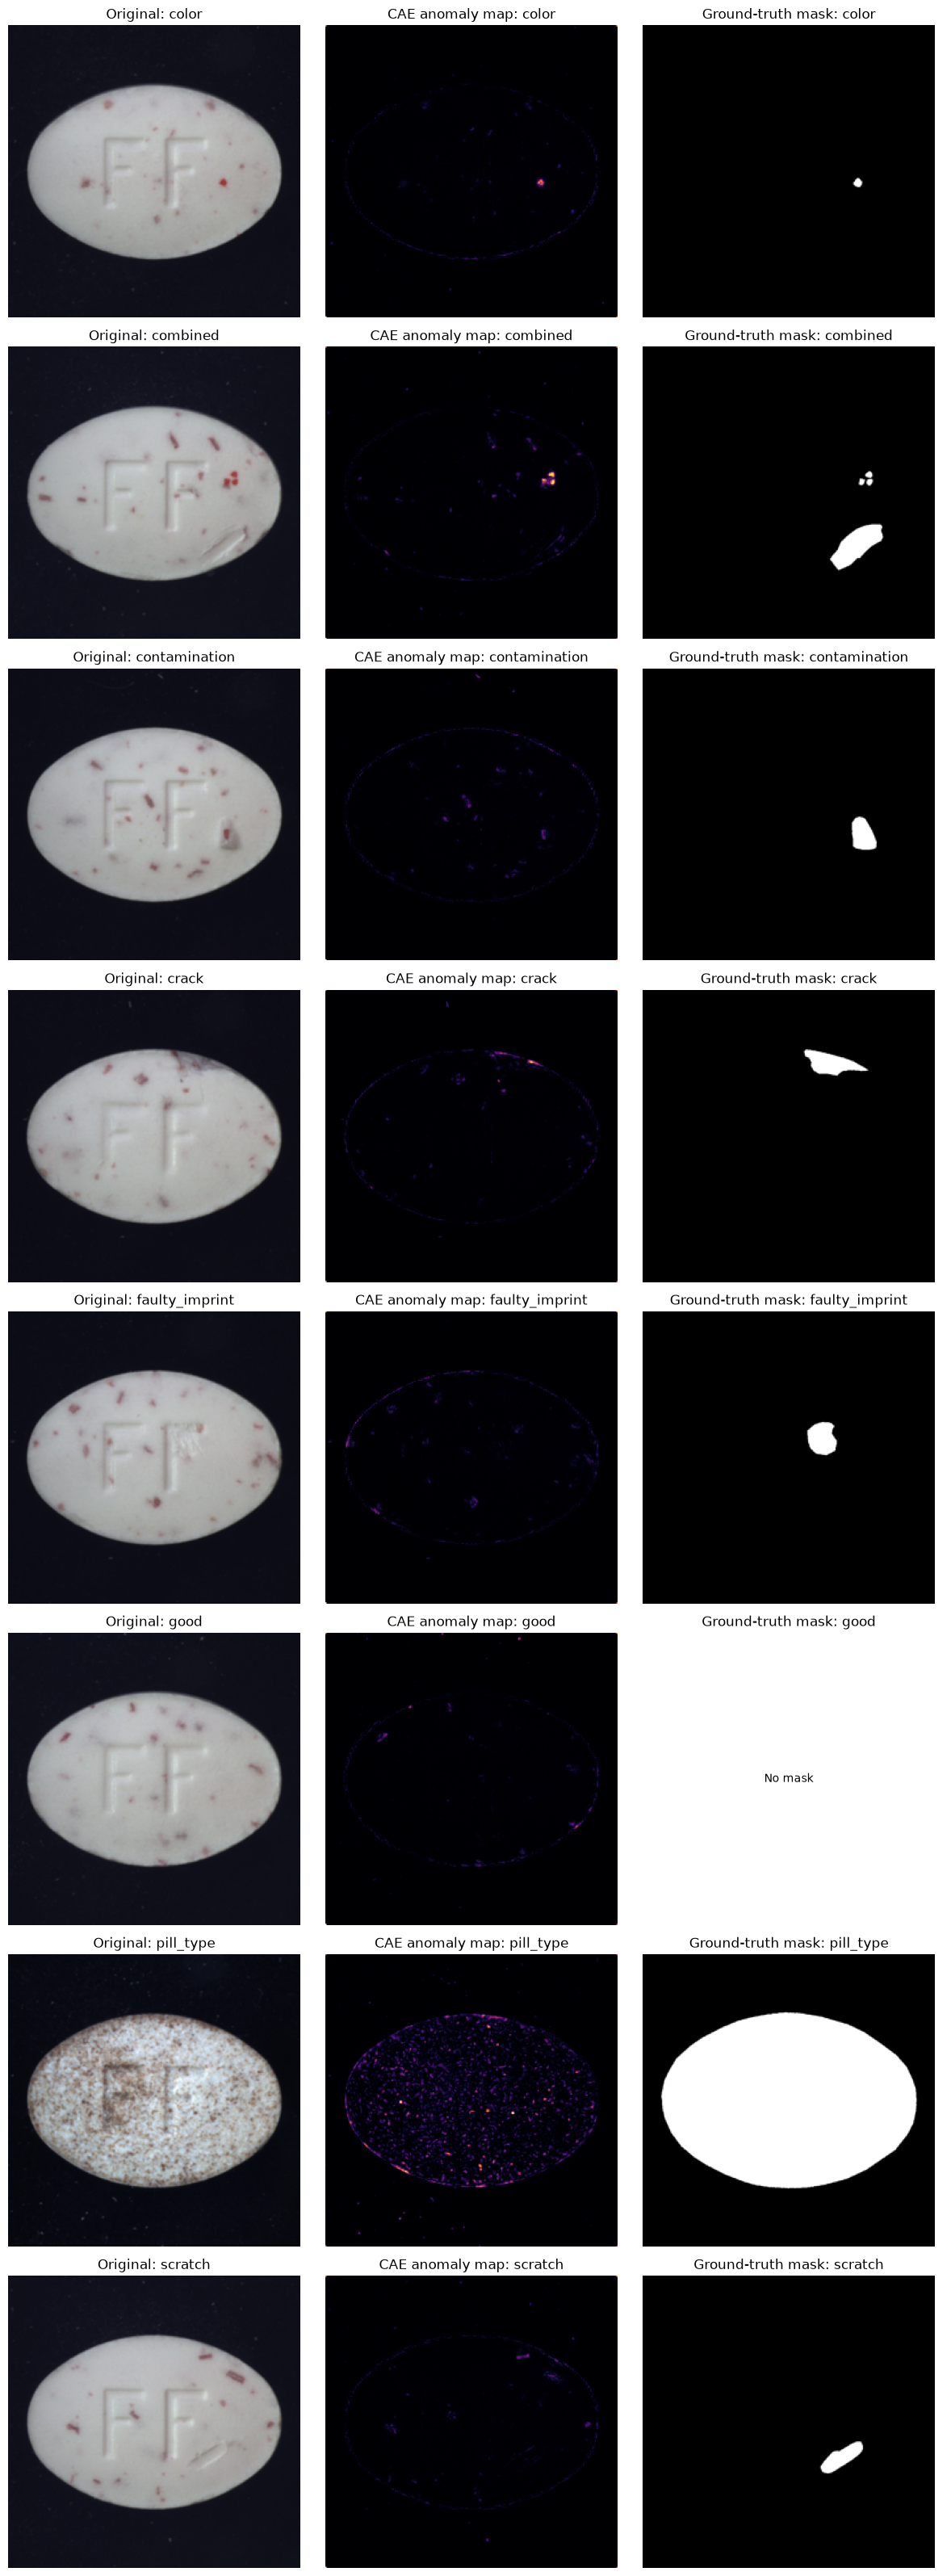

In [28]:
# แสดงภาพตัวอย่างจากทุกคลาสในชุดทดสอบ
# anomaly_maps และ test_paths ต้องสร้างไว้แล้วจากเซลล์ประเมินผล

categories = sorted({
    path.parent.name
    for path in test_paths
})

# เลือกภาพแรกของแต่ละคลาส
sample_indices = []
for category in categories:
    index = next(
        i for i, path in enumerate(test_paths)
        if path.parent.name == category
    )
    sample_indices.append(index)

# เรียงเป็นแถว แถวละ 3 ภาพ: ภาพจริง, anomaly map, mask
fig, axes = plt.subplots(
    len(sample_indices),
    3,
    figsize=(12, 4 * len(sample_indices)),
    squeeze=False
)

for row, index in enumerate(sample_indices):
    image_path = test_paths[index]
    category = image_path.parent.name

    # โหลดภาพและ mask ให้มีขนาดเดียวกับ anomaly map
    original = Image.open(image_path).convert("RGB").resize(
        (IMAGE_SIZE, IMAGE_SIZE)
    )
    mask_path = MASK_DIR / category / f"{image_path.stem}_mask.png"

    axes[row, 0].imshow(original)
    axes[row, 0].set_title(f"Original: {category}")

    axes[row, 1].imshow(anomaly_maps[index], cmap="inferno")
    axes[row, 1].set_title(f"CAE anomaly map: {category}")

    if mask_path.exists():
        mask = Image.open(mask_path).convert("L").resize(
            (IMAGE_SIZE, IMAGE_SIZE)
        )
        axes[row, 2].imshow(mask, cmap="gray")
        axes[row, 2].set_title(f"Ground-truth mask: {category}")
    else:
        axes[row, 2].text(
            0.5, 0.5, "No mask",
            ha="center", va="center"
        )
        axes[row, 2].set_title(f"Ground-truth mask: {category}")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()

In [29]:
# สร้าง image score จากค่าเฉลี่ยของพิกเซลที่มี reconstruction error สูงสุด
# เลือก threshold จาก percentile ของ validation-good เท่านั้น
from sklearn.metrics import roc_auc_score, precision_recall_fscore_support, confusion_matrix

@torch.no_grad()
def predict_maps(loader):
    model.eval()
    maps = []
    for batch in loader:
        # Dataset คืน tensor ตรง ๆ; รองรับกรณี loader คืน tuple/list ด้วย
        images = batch[0] if isinstance(batch, (tuple, list)) else batch
        images = images.to(device, non_blocking=True)
        recon = model(images)
        error = (images - recon).pow(2).mean(dim=1)
        maps.extend(error.cpu().numpy())
    return [np.asarray(m, dtype=np.float32) for m in maps]

val_maps = predict_maps(val_loader)
val_image_scores = np.array([np.quantile(m, 0.99) for m in val_maps])

# ตั้งค่าได้ เช่น 0.05 หมายถึงยอมให้ภาพปกติ validation ประมาณ 5% เกิน threshold
TARGET_FALSE_POSITIVE_RATE = 0.05
image_threshold = float(np.quantile(val_image_scores, 1 - TARGET_FALSE_POSITIVE_RATE))
print(f'Image threshold จาก validation-good: {image_threshold:.6f}')
print(f'Target false-positive rate: {TARGET_FALSE_POSITIVE_RATE:.1%}')

Image threshold จาก validation-good: 0.003881
Target false-positive rate: 5.0%


In [ ]:
import pandas as pd
# ประเมิน Test หลังจาก freeze threshold แล้วเท่านั้น
test_paths = sorted(
    p for class_dir in TEST_DIR.iterdir() if class_dir.is_dir()
    for p in class_dir.glob('*.png')
)
test_dataset = PillDataset(test_paths, IMAGE_SIZE)
test_loader = DataLoader(test_dataset, batch_size=1, shuffle=False, num_workers=0)
test_maps = predict_maps(test_loader)

# label ระดับภาพ: good=0, คลาสตำหนิ=1
y_true_image = np.array([int(p.parent.name != 'good') for p in test_paths])
y_score_image = np.array([np.quantile(m, 0.99) for m in test_maps])
y_pred_image = (y_score_image >= image_threshold).astype(np.uint8)
image_auroc = roc_auc_score(y_true_image, y_score_image)
precision, recall, f1, _ = precision_recall_fscore_support(
    y_true_image, y_pred_image, average='binary', zero_division=0
)
tn, fp, fn, tp = confusion_matrix(y_true_image, y_pred_image, labels=[0, 1]).ravel()
specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0

# Pixel AUROC: resize GT mask nearest-neighbor
pixel_scores, pixel_labels = [], []
for path, anomaly_map in zip(test_paths, test_maps):
    if path.parent.name == 'good':
        gt = np.zeros((IMAGE_SIZE, IMAGE_SIZE), dtype=np.uint8)
    else:
        mask_path = MASK_DIR / path.parent.name / f'{path.stem}_mask.png'
        if not mask_path.exists():
            continue  # ไม่รวมภาพที่ไม่มี mask ใน pixel-level metric
        gt_img = Image.open(mask_path).convert('L').resize(
            (IMAGE_SIZE, IMAGE_SIZE), resample=Image.Resampling.NEAREST
        )
        gt = (np.asarray(gt_img) > 0).astype(np.uint8)
    pixel_scores.append(anomaly_map.ravel())
    pixel_labels.append(gt.ravel())

pixel_scores = np.concatenate(pixel_scores)
pixel_labels = np.concatenate(pixel_labels)
pixel_auroc = roc_auc_score(pixel_labels, pixel_scores)

metrics = pd.DataFrame([
    {'Metric': 'Image AUROC', 'Value': image_auroc},
    {'Metric': 'Image Precision (validation threshold)', 'Value': precision},
    {'Metric': 'Image Recall (validation threshold)', 'Value': recall},
    {'Metric': 'Image Specificity (validation threshold)', 'Value': specificity},
    {'Metric': 'Image F1 (validation threshold)', 'Value': f1},
    {'Metric': 'Pixel AUROC', 'Value': pixel_auroc},
])
display(metrics)
print('Confusion matrix [ [TN, FP], [FN, TP] ]:')
print(confusion_matrix(y_true_image, y_pred_image))
print(f'Image threshold (เลือกจาก validation): {image_threshold:.6f}')

,Metric,Value
0,Image AUROC,0.703764
1,Image Precision (validation threshold),0.933333
2,Image Recall (validation threshold),0.198582
3,Image Specificity (validation threshold),0.923077
4,Image F1 (validation threshold),0.327485
5,Pixel AUROC,0.863058


Confusion matrix [ [TN, FP], [FN, TP] ]:
[[ 24   2]
 [113  28]]
Image threshold (เลือกจาก validation): 0.003881
